# TP 4 — Assembler et entraîner un mini-Transformer

**Cours sur les Transformers — CY Tech · Travaux pratiques**

---

## Objectif

Assembler les briques des TP 1 à 3 en un **modèle de langage complet de type GPT**, l'entraîner sur Tiny Shakespeare au niveau des caractères, puis lui faire générer du texte.

```
caractères ──► embeddings de token + de position
                           │
              ┌────────────▼────────────┐
              │ LayerNorm → attention   │  « communication » entre tokens
   × 4 blocs  │      + résiduel         │
              │ LayerNorm → MLP         │  « calcul » sur chaque token
              │      + résiduel         │
              └────────────┬────────────┘
                     LayerNorm finale
                           │
             unembedding (lm_head) → logits → softmax → prochain caractère
```

**Résultat attendu** (énoncé) : des pertes d'entraînement et de validation qui diminuent, puis environ 2 000 caractères générés dans un style progressivement reconnaissable, sans exiger un anglais correct.

## Répartition du travail

| | Contenu | Dans ce notebook |
|---|---|---|
| **Fourni** | chargement, dropout, évaluation, optimiseur | repris tel quel |
| **À compléter** | attention, résiduels, embeddings, loss, génération | complété, chaque blanc est signalé par `# ✅` |
| **À commenter** | toutes les formes de tenseurs | en commentaire, et vérifié par du code |

Chaque étape est suivie des **réponses aux questions d'interprétation** de l'énoncé.

## Exécution

`Exécution → Modifier le type d'exécution → GPU T4`, puis `Exécution → Tout exécuter`. Avec un GPU : environ 5 minutes en tout, entraînement principal et expériences compris. Sans GPU, le notebook fonctionne mais l'entraînement principal prend plusieurs dizaines de minutes ; les expériences de la partie 11 réduisent alors automatiquement leur nombre d'itérations.

## Étape 0 — Préparer le notebook

### Les constantes

Les classes des étapes suivantes lisent ces constantes : il faut exécuter le notebook dans l'ordre.

In [1]:
import os
import time
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

import torch
import torch.nn as nn
from torch.nn import functional as F

torch.manual_seed(1337)

batch_size = 16        # B : nombre de séquences traitées en parallèle
block_size = 32        # T max : longueur maximale du contexte
max_iters = 5000
eval_interval = 100
learning_rate = 1e-3
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 64            # C : dimension des embeddings
n_head = 4
n_layer = 4
dropout = 0.0

assert n_embd % n_head == 0
print(device)

cuda


In [2]:
# Style commun des graphiques : fond clair, grille discrète, couleurs lisibles par les daltoniens
SURFACE, INK, INK2, MUTED, GRILLE, AXE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]   # bleu, orange, aqua
RAMPE_BLEUE = ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXE, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelcolor": INK2, "xtick.color": AXE, "ytick.color": AXE,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.axisbelow": True, "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK2,
    "font.size": 10,
})

### Repris du TP 1 : le corpus, `encode` / `decode`, le découpage et `get_batch`

Seul ajout par rapport au TP 1 : `get_batch` envoie les tenseurs sur le `device` (GPU si disponible).

In [3]:
url = ("https://raw.githubusercontent.com/karpathy/"
       "char-rnn/master/data/tinyshakespeare/input.txt")
if not os.path.exists("input.txt"):
    urlretrieve(url, "input.txt")

with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()

chars = sorted(list(set(text)))
vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]            # texte -> liste d'entiers
decode = lambda ids: ''.join([itos[i] for i in ids])  # liste d'entiers -> texte

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]


def get_batch(split):
    source = train_data if split == "train" else val_data
    starts = torch.randint(len(source) - block_size, (batch_size,))
    x = torch.stack([source[i : i + block_size] for i in starts])          # (B, T)
    y = torch.stack([source[i + 1 : i + block_size + 1] for i in starts])  # (B, T), décalé d'un cran
    return x.to(device), y.to(device)


print(f"{len(text):,} caractères · vocabulaire de {vocab_size} caractères")
print(f"train : {len(train_data):,} tokens · validation : {len(val_data):,} tokens")
xb, yb = get_batch("train")
print(f"xb : {tuple(xb.shape)}   yb : {tuple(yb.shape)}")
assert decode(encode("hii there")) == "hii there"

1,115,394 caractères · vocabulaire de 65 caractères
train : 1,003,854 tokens · validation : 111,540 tokens
xb : (16, 32)   yb : (16, 32)


### ✅ Réponses — étape 0

**Calculez $d_h = n_{emb} / n_{head}$.** $d_h = 64 / 4 = 16$ : chaque tête travaille dans un espace de 16 dimensions, et les 4 têtes concaténées redonnent les 64 dimensions de l'embedding.

**Combien de tokens contient un batch ?** $B \times T = 16 \times 32 = 512$ tokens. Comme chaque position prédit le caractère suivant (TP 1, étape 3), un batch fournit **512 exemples de prédiction** traités en parallèle.

**Sur CPU, quelle variable réduire d'abord pour tester ?** `max_iters`, le nombre d'itérations : il fixe directement la durée totale, sans changer le modèle. Juste après vient `eval_iters` : chaque évaluation coûte $2 \times 200 = 400$ passages avant, répétés toutes les 100 itérations, soit environ quatre fois plus de passages avant que l'entraînement lui-même. Réduire `batch_size` ou `block_size` accélère aussi, mais change le problème appris.

## Étape 1 — Coder une tête d'attention

On reprend exactement les opérations validées au TP 2 : scores $QK^\top$, mise à l'échelle par $1/\sqrt{d_h}$, masque causal, softmax, puis mélange des *values*.

Une ligne est ajoutée pour la partie 10 : la tête garde une copie de ses derniers poids d'attention, afin qu'on puisse les afficher après l'entraînement.

In [4]:
class Head(nn.Module):
    """Une tête d'auto-attention causale."""

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer(
            'tril', torch.tril(torch.ones(block_size, block_size))
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape                                         # x : (B, T, C)
        k, q = self.key(x), self.query(x)                         # (B, T, hs)
        wei = q @ k.transpose(-2, -1) * k.size(-1)**-0.5          # ✅ (B, T, hs) @ (B, hs, T) -> (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))   # ✅ le futur reçoit -inf
        wei = F.softmax(wei, dim=-1)                              # (B, T, T), chaque ligne somme à 1
        self.poids_attention = wei.detach()                       # copie pour l'analyse (partie 10)
        wei = self.dropout(wei)
        v = self.value(x)                                         # (B, T, hs)
        return wei @ v                                            # ✅ (B, T, T) @ (B, T, hs) -> (B, T, hs)

### ✅ Réponses — étape 1

**Pour `x` de forme (16, 32, 64)** : `q`, `k` et `v` sont de forme (16, 32, 16), `wei` de forme (16, 32, 32), la sortie de forme (16, 32, 16). La vérification par le code est faite dans la partie « Test court ».

**Pourquoi `k.size(-1)` plutôt que $C$ pour le facteur d'échelle ?** Le produit scalaire $q \cdot k$ est une somme de $d_h$ termes. Sa variance vaut donc environ $d_h$ (TP 2, étape 6), et c'est par $\sqrt{d_h}$ qu'il faut diviser pour la ramener à 1. `k.size(-1)` vaut $d_h = 16$. Diviser par $\sqrt{C} = \sqrt{64}$ écraserait trop les scores : la softmax deviendrait presque uniforme et l'attention moins sélective.

**Pourquoi tronquer `tril[:T, :T]` ?** Le masque est construit une fois pour toutes à la taille maximale `block_size × block_size`. Mais la séquence reçue peut être plus courte. C'est le cas pendant la **génération** : on démarre avec un seul caractère, et le contexte grandit jusqu'à `block_size`. Le masque doit avoir exactement la forme (T, T) des scores `wei`, sinon l'opération échoue.

## Étape 2 — Combiner plusieurs têtes

In [5]:
class MultiHeadAttention(nn.Module):
    """Plusieurs têtes en parallèle, concaténées puis projetées (W_O)."""

    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([
            Head(head_size) for _ in range(num_heads)
        ])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat(
            [h(x) for h in self.heads], dim=-1                    # ✅ 4 × (B, T, 16) -> (B, T, 64)
        )
        return self.dropout(self.proj(out))                       # (B, T, 64) -> (B, T, 64)

### ✅ Réponses — étape 2

**Pourquoi concaténer sur la dernière dimension ?** Chaque tête produit, pour **les mêmes** B séquences et T positions, un vecteur de $d_h$ composantes. Les deux premières dimensions (B, T) sont communes à toutes les têtes. On met donc bout à bout les **caractéristiques** de chaque position, et chaque token récupère les 4 « points de vue » en un seul vecteur de 64 composantes. Concaténer sur la dimension 1 mettrait les têtes les unes derrière les autres comme s'il s'agissait de positions supplémentaires, ce qui n'a pas de sens. La projection $W_O$ mélange ensuite les informations des têtes (cours, slides 48 et 51).

**Et si $n_{emb}$ n'était pas divisible par $n_{head}$ ?** Avec `head_size = n_embd // n_head`, la concaténation aurait $n_{head} \times d_h < n_{emb}$ composantes. Par exemple, 64 // 5 = 12 et 5 × 12 = 60. La projection `nn.Linear(n_embd, n_embd)` attend 64 entrées et lèverait une erreur de dimensions. Et même en adaptant la projection, la sortie doit retrouver la dimension $C$ pour l'addition résiduelle. C'est le rôle de l'`assert` de l'étape 0.

## Étape 3 — Assembler un bloc

Le MLP est celui du TP 3 ($C \to 4C \to C$). Le bloc suit l'organisation **pré-norm** : LayerNorm **avant** chaque sous-couche, puis addition résiduelle (cours, slide 59).

In [6]:
class FeedForward(nn.Module):
    """MLP appliqué indépendamment à chaque token : C -> 4C -> C."""

    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)                                        # (B, T, C) -> (B, T, C)


class Block(nn.Module):
    """Bloc Transformer : communication (attention) puis calcul (MLP)."""

    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))       # ✅ communication : les tokens échangent de l'information
        x = x + self.ffwd(self.ln2(x))     # ✅ calcul : chaque token est transformé séparément
        return x                           # (B, T, C)

### ✅ Réponses — étape 3

**Dans quel ordre appliquer LayerNorm, attention/MLP et addition ?** Dans l'ordre **normaliser → sous-couche → additionner** : `x = x + sous_couche(LayerNorm(x))`. La normalisation porte sur l'**entrée** de la sous-couche, et c'est le `x` **non normalisé** qu'on additionne. Ainsi, le « chemin résiduel » $x \to x + \Delta x \to \dots$ traverse les 4 blocs sans jamais être modifié par une normalisation. Le gradient le parcourt directement jusqu'aux embeddings, ce qui stabilise l'entraînement d'un réseau profond (TP 3, étape 5).

**À quoi correspondent « communication » et « calcul » ?**

- **Communication = l'attention multi-têtes.** C'est la **seule** opération où un token reçoit de l'information des autres tokens, ceux qui le précèdent, à cause du masque causal.
- **Calcul = le MLP.** Il agit sur chaque position indépendamment (TP 3) et transforme ce que le token a récupéré. Dans le cours, c'est là que le modèle mobilise des associations apprises (slides 56 à 69).

Un bloc alterne donc « je regarde le contexte » puis « je réfléchis à ce que j'ai vu ».

## Étapes 4, 5 et 6 — Le modèle complet

Dans un notebook, une classe doit tenir dans une seule cellule. Les trois étapes de l'énoncé sont donc réunies ici et repérées en commentaire : les couches (étape 4), le passage avant et la loss (étape 5), la génération (étape 6).

La classe garde le nom `BigramLanguageModel` de l'énoncé, mais ce n'est plus un bigramme : chaque prédiction dépend maintenant de jusqu'à 32 caractères de contexte.

In [7]:
class BigramLanguageModel(nn.Module):

    # ----- Étape 4 : les couches ------------------------------------------------
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(
            vocab_size, n_embd                       # ✅ (65, 64) : un vecteur par caractère
        )
        self.position_embedding_table = nn.Embedding(
            block_size, n_embd                       # ✅ (32, 64) : un vecteur par position
        )
        self.blocks = nn.Sequential(*[
            Block(n_embd, n_head=n_head)
            for _ in range(n_layer)
        ])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)  # ✅ unembedding : (64 -> 65)

    # ----- Étape 5 : passage avant et loss --------------------------------------
    def forward(self, idx, targets=None):
        B, T = idx.shape

        tok_emb = self.token_embedding_table(idx)                 # (B, T, C)
        pos = torch.arange(T, device=idx.device)                  # (T,)
        pos_emb = self.position_embedding_table(pos)              # (T, C)

        x = tok_emb + pos_emb                                     # ✅ (B, T, C) + (T, C) -> (B, T, C)
        x = self.blocks(x)                                        # (B, T, C)
        x = self.ln_f(x)                                          # (B, T, C)
        logits = self.lm_head(x)                                  # (B, T, vocab_size)

        if targets is None:
            loss = None
        else:
            logits = logits.reshape(B * T, vocab_size)            # (B*T, vocab_size)
            targets = targets.reshape(B * T)                      # (B*T,)
            loss = F.cross_entropy(logits, targets)               # ✅
        return logits, loss

    # ----- Étape 6 : générer avec un contexte limité ----------------------------
    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]                       # ✅ au plus block_size derniers tokens
            logits, _ = self(idx_cond)                            # (B, T, vocab_size)

            logits = logits[:, -1, :]                             # ✅ (B, vocab_size) : dernière position
            probs = F.softmax(logits, dim=-1)                     # (B, vocab_size)
            idx_next = torch.multinomial(
                probs, num_samples=1                              # (B, 1) : tirage d'un caractère
            )
            idx = torch.cat((idx, idx_next), dim=1)               # (B, T+1)
        return idx

### ✅ Réponses — étape 4

**Dimensions des trois matrices d'embedding / unembedding** (avec `vocab_size = 65`) :

| Matrice | Forme | Paramètres | Rôle |
|---|---|---|---|
| `token_embedding_table` | (65, 64) | 4 160 | identité du caractère |
| `position_embedding_table` | (32, 64) | 2 048 | place dans le contexte |
| `lm_head` | poids (65, 64) + biais 65 | 4 225 | des 64 dimensions vers les 65 logits |

**Pourquoi `lm_head` n'est-il plus confondu avec l'embedding ?** Dans le bigramme du TP 1, la table d'embedding était de taille $C_{vocab} \times C_{vocab}$ : la ligne du caractère courant **était** directement le vecteur de logits du caractère suivant. Une seule matrice faisait les deux métiers, sans espace intermédiaire.

Désormais, l'embedding projette chaque caractère dans un espace de travail de dimension 64, où l'attention et les MLP enrichissent sa représentation. Il faut ensuite une matrice distincte pour revenir de cet espace vers une distribution sur les 65 caractères : c'est l'**unembedding** (cours, slides 26 à 28). Ce n'est plus le caractère courant qui décide seul de la prédiction, mais toute la représentation contextualisée construite par les blocs. (Certains modèles, comme GPT-2, partagent quand même les poids de l'embedding et de l'unembedding, une technique appelée *weight tying* ; ce n'est pas obligatoire.)

### ✅ Réponses — étape 5

**Quelle règle de broadcasting permet l'addition des embeddings ?** PyTorch aligne les dimensions **en partant de la fin**. `tok_emb` est de forme (B, T, C) et `pos_emb` de forme (T, C) : les deux dernières dimensions coïncident. `pos_emb` est alors traité comme s'il avait une dimension de batch de taille 1, recopiée B fois. Chaque séquence du batch reçoit ainsi **le même** vecteur de position à la même place : la position 3 a le même embedding de position dans toutes les séquences, ce qui est voulu.

**Pourquoi ne pas aplatir les logits lors de la génération ?** L'aplatissement en (B·T, vocab) n'existe que pour satisfaire `F.cross_entropy`, qui attend une liste de prédictions et une liste de cibles. Pendant la génération, il n'y a pas de cible, et l'on a besoin de **retrouver la structure** (B, T, vocab) pour sélectionner la dernière position de chaque séquence avec `logits[:, -1, :]`. Une fois aplati, on ne saurait plus quelle ligne correspond à quelle séquence ni à quelle position.

### ✅ Réponses — étape 6

**Pourquoi `@torch.no_grad()` ?** Pendant la génération, on n'entraîne pas : inutile de mémoriser le graphe de calcul pour une rétropropagation. Désactiver le suivi des gradients économise de la mémoire (sinon chaque étape de la boucle allongerait le graphe) et accélère le calcul.

**Pourquoi échantillonner avec `multinomial` plutôt que prendre `argmax` ?** `argmax` est **déterministe** : pour un même contexte, il choisit toujours le même caractère. Le texte tombe vite dans des boucles (« the the the… ») et ne produit que la suite la plus probable, souvent banale. Tirer au hasard selon les probabilités produit un texte **varié** qui reflète toute la distribution apprise : un caractère à 30 % sortira environ une fois sur trois (cours, slide 6). La boucle « lire le contexte → prédire → tirer → réinjecter » est la **génération autorégressive** (slide 4).

## Test court avant l'entraînement complet

L'énoncé (étape 9) conseille de lancer d'abord un test très court. On vérifie trois choses avant de dépenser du calcul :

1. **les formes** des tenseurs à chaque étage ;
2. **la loss initiale** : un modèle qui ne sait rien répartit sa probabilité à peu près uniformément sur 65 caractères. La loss doit donc valoir environ $-\ln(1/65) = \ln 65 \approx 4{,}17$. Une valeur très différente signale une erreur ;
3. **le texte généré avant entraînement**, qui sera comparé au texte final.

In [8]:
torch.manual_seed(1337)
model = BigramLanguageModel().to(device)
print(sum(p.numel() for p in model.parameters()) / 1e6, 'M parameters')

# 1. Formes, étage par étage
xb, yb = get_batch('train')
with torch.no_grad():
    tete = model.blocks[0].sa.heads[0]
    x0 = model.token_embedding_table(xb) + model.position_embedding_table(torch.arange(block_size, device=device))
    print(f"\nentrée idx                 : {tuple(xb.shape)}")
    print(f"embeddings token + position : {tuple(x0.shape)}")
    print(f"q, k, v d'une tête          : {tuple(tete.query(x0).shape)}")
    print(f"sortie d'une tête           : {tuple(tete(x0).shape)}   poids wei : {tuple(tete.poids_attention.shape)}")
    print(f"sortie multi-têtes          : {tuple(model.blocks[0].sa(x0).shape)}")
    print(f"sortie d'un bloc            : {tuple(model.blocks[0](x0).shape)}")
    logits, loss = model(xb, yb)
    print(f"logits (aplatis pour la loss) : {tuple(logits.shape)}")

    # 2. Loss initiale
    print(f"\nloss initiale = {loss.item():.3f}   (attendu ≈ ln({vocab_size}) = {np.log(vocab_size):.3f})")

    # Les poids d'attention d'une ligne somment à 1 et le futur reçoit 0
    w = tete.poids_attention[0]
    assert torch.allclose(w.sum(-1), torch.ones(block_size, device=device), atol=1e-5)
    assert torch.all(w.triu(diagonal=1) == 0)
    print("poids d'attention : lignes de somme 1, aucun poids vers le futur ✓")

# 3. Génération avant entraînement
context = torch.zeros((1, 1), dtype=torch.long, device=device)
texte_avant = decode(model.generate(context, max_new_tokens=300)[0].tolist())
print("\n--- Texte généré AVANT entraînement ---\n" + texte_avant)

0.209729 M parameters

entrée idx                 : (16, 32)
embeddings token + position : (16, 32, 64)
q, k, v d'une tête          : (16, 32, 16)
sortie d'une tête           : (16, 32, 16)   poids wei : (16, 32, 32)
sortie multi-têtes          : (16, 32, 64)
sortie d'un bloc            : (16, 32, 64)
logits (aplatis pour la loss) : (512, 65)

loss initiale = 4.382   (attendu ≈ ln(65) = 4.174)
poids d'attention : lignes de somme 1, aucun poids vers le futur ✓

--- Texte généré AVANT entraînement ---

?YfzxbDkRZ'Nzc.wj,ZTkOLFL,yptK
b:!PeCkbBbzAU3eXaSKgO-33jM:c?gL3auhXbYVXJtpXfNuwqcJ,$G.t?Vc dXl!DwaLeNFwccHPpRWk,fDEdaYzxzC$omX
Yow&$-MtofViEphB!H&V!OW;Kd!lNZ,Keg irYe-EOnUciK;lxW;HFGidroG EsSXUB;qWklJ.JGDW.3eWjbm!pelJljnFApVcu.$-huE3qcVcJvbN:pUup;Mnii'X3Uwty.OJlvBPUHI.3BfopeY-lgvIEjVkgDmlqwJdlNctS?k


Avant l'entraînement, le texte est une suite de caractères tirés presque uniformément : majuscules, ponctuation et retours à la ligne mélangés au hasard. Le modèle compte environ **0,21 million de paramètres**, soit environ 835 000 fois moins que GPT-3 (175 milliards, cours slide 71), **pour exactement la même architecture** : embeddings, blocs attention + MLP, LayerNorm, unembedding.

## Étapes 7 et 8 — Évaluer puis entraîner

`estimate_loss` est fournie par l'énoncé. La boucle d'entraînement suit les quatre temps du cours : forward, loss, backward, mise à jour (slide 82). On enregistre en plus les pertes estimées pour les tracer.

In [9]:
@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

In [10]:
torch.manual_seed(1337)
model = BigramLanguageModel().to(device)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=learning_rate
)

historique = []
t0 = time.time()
for iteration in range(max_iters):
    if iteration % eval_interval == 0:
        pertes = estimate_loss()
        historique.append({"itération": iteration, "train": pertes['train'].item(), "val": pertes['val'].item()})
        if iteration % (10 * eval_interval) == 0:
            print(f"itération {iteration:5d} : train {pertes['train']:.4f}, val {pertes['val']:.4f}"
                  f"   ({time.time() - t0:.0f} s)")

    xb, yb = get_batch('train')
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()                    # ✅ rétropropagation : gradient de la loss pour chaque paramètre
    optimizer.step()                   # ✅ mise à jour de tous les paramètres

pertes = estimate_loss()
historique.append({"itération": max_iters, "train": pertes['train'].item(), "val": pertes['val'].item()})
historique = pd.DataFrame(historique)
duree_entrainement = time.time() - t0
print(f"itération {max_iters:5d} : train {pertes['train']:.4f}, val {pertes['val']:.4f}"
      f"   — entraînement terminé en {duree_entrainement:.0f} s")

itération     0 : train 4.4109, val 4.4016   (3 s)
itération  1000 : train 2.0562, val 2.0895   (58 s)
itération  2000 : train 1.8529, val 1.9716   (112 s)
itération  3000 : train 1.7752, val 1.9070   (165 s)
itération  4000 : train 1.7075, val 1.8554   (221 s)
itération  5000 : train 1.6622, val 1.8201   — entraînement terminé en 276 s


### ✅ Réponses — étapes 7 et 8

**Pourquoi appeler `model.eval()` puis `model.train()` ?** Certaines couches ne se comportent pas de la même façon à l'entraînement et à l'évaluation. C'est surtout le cas du **dropout**, qui éteint des neurones au hasard pendant l'entraînement mais doit être désactivé pour mesurer le modèle réel. `model.eval()` bascule en mode évaluation avant de mesurer ; `model.train()` revient en mode entraînement avant de reprendre l'apprentissage. Ici `dropout = 0.0`, donc cela ne change rien aux chiffres, mais c'est indispensable dès qu'on augmente le dropout (partie 11). Oublier `model.train()` entraînerait le modèle sans sa régularisation ; oublier `model.eval()` fausserait les pertes mesurées.

Autre point : la perte affichée est une **moyenne sur 200 mini-batchs** et non la perte d'un seul batch, qui serait très bruitée. C'est pour cela que l'évaluation est séparée de la boucle.

**Si la loss train baisse mais que la loss validation remonte ?** C'est du **sur-apprentissage** : le modèle mémorise des particularités du texte d'entraînement qui ne se retrouvent pas dans la validation (cours NLP, slide 26). Les remèdes : arrêter l'entraînement au minimum de la validation (*early stopping*), augmenter le `dropout` ou le weight decay, réduire la taille du modèle, ou ajouter des données.

## Étape 9 — Résultats

### 9.1 Les courbes de perte

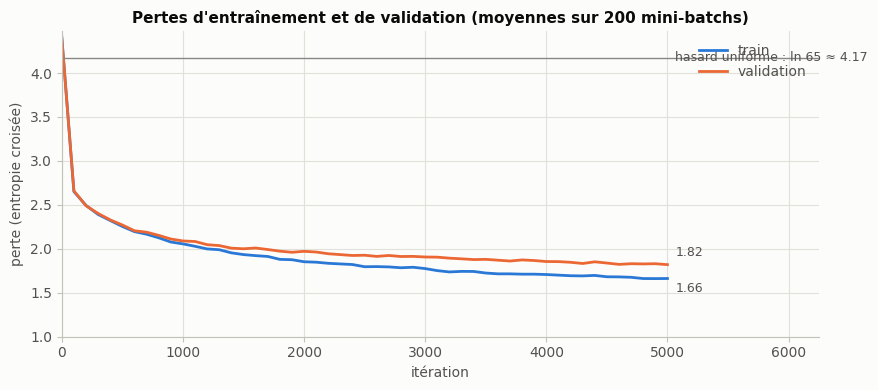

Perte finale : train 1.662, validation 1.820 (écart +0.158)
Minimum de validation : 1.820 à l'itération 5000


In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(historique["itération"], historique["train"], color=SERIES[0], label="train")
ax.plot(historique["itération"], historique["val"], color=SERIES[1], label="validation")
ax.axhline(np.log(vocab_size), color=MUTED, linewidth=1)
ax.text(max_iters, np.log(vocab_size), f"  hasard uniforme : ln {vocab_size} ≈ {np.log(vocab_size):.2f}",
        va="center", color=INK2, fontsize=9)
for col, couleur in [("train", SERIES[0]), ("val", SERIES[1])]:
    fin = historique[col].iloc[-1]
    ax.annotate(f"{fin:.2f}", xy=(max_iters, fin), xytext=(6, -10 if col == "train" else 6),
                textcoords="offset points", color=INK2, fontsize=9)
ax.set_xlabel("itération")
ax.set_ylabel("perte (entropie croisée)")
ax.set_ylim(1, np.log(vocab_size) + 0.3)
ax.set_xlim(0, max_iters * 1.25)
ax.legend(loc="upper right")
ax.set_title("Pertes d'entraînement et de validation (moyennes sur 200 mini-batchs)")
plt.tight_layout()
plt.show()

ecart = historique["val"].iloc[-1] - historique["train"].iloc[-1]
i_min = historique["val"].idxmin()
print(f"Perte finale : train {historique['train'].iloc[-1]:.3f}, validation {historique['val'].iloc[-1]:.3f}"
      f" (écart {ecart:+.3f})")
print(f"Minimum de validation : {historique.loc[i_min, 'val']:.3f} à l'itération {historique.loc[i_min, 'itération']}")

**Comment lire les courbes.**

- **Départ vers 4,17** : le modèle ne sait rien, c'est la perte du hasard uniforme sur 65 caractères.
- **Chute rapide les premières centaines d'itérations** : le modèle apprend d'abord les fréquences des caractères (beaucoup d'espaces, de `e`), puis les associations immédiates (après `q` vient `u`). C'est ce qu'un bigramme sait déjà faire : le bigramme du TP 1 plafonne vers une perte de 2,5.
- **Descente lente ensuite**, sous le niveau du bigramme : c'est le gain du **contexte**. Grâce à l'attention, chaque prédiction s'appuie sur jusqu'à 32 caractères (mots en cours, nom du locuteur, structure des répliques). Avec ces réglages, on attend une perte de validation finale de l'ordre de 1,8 à 2,0.
- **L'écart entre train et validation** mesure le sur-apprentissage. S'il reste faible (de l'ordre de 0,1 à 0,2) et que la validation baisse encore à la fin, le modèle **sous-apprend** plutôt : il gagnerait à être plus gros ou entraîné plus longtemps. Si la validation remonte, il faut régulariser (partie 11).

### 9.2 Générer 2 000 caractères

In [12]:
torch.manual_seed(1337)
context = torch.zeros((1, 1), dtype=torch.long, device=device)
result = model.generate(context, max_new_tokens=2000)
texte_apres = decode(result[0].tolist())
print(texte_apres)


And they bridle.

SOLORETESH:

becannoblanouge.
Stirt'd the gatause: thith foul him tot?

MEXENIUS:
Whrink my feand, to zown heavens, tofficion!
But where in at misters, I in latest in ov the does flow.

PAULINA:
Welll no me us thus, congivy: tugh are thee you love.
In Bodiet-lives, but you, thou again Willond,
ICeriage to them, and The shire-strown
gorn; thuse knome,
Tursefore;
And his shall dying of the padere?

KING HENRY-PLINCE:
You have adval the Eartune:
in courreasanny Ire to chan you!
My fire noth, I guilts you haste?
 so a cemssed-spent betwerting, and thou such swond the beggent of
confespy that that lome
Is as detter in stroesed Peepent over:
Hendst comment if meed; buse stings his remes to Lony,
Who lovescess is good duke one.

xut Corach!
Hear that fraving with some. Do year For these late.

PETHIBY:
He hone,-his I it him.

CORIONA:
I watey, if I doot, iundethorn, thee summe will these whoe than the rugless welll keep you have the is.

BENBOLIO:
You the glear fly excents.

**Avant / après.** Le texte d'avant entraînement était du bruit de caractères. Après 5 000 itérations, on doit reconnaître la **forme** d'une pièce de théâtre :

- des noms en majuscules suivis de `:` en début de réplique ;
- des répliques séparées par des lignes vides ;
- des vers courts avec majuscule en début de ligne ;
- des mots anglais fréquents (*the*, *and*, *my lord*, *thou*) et des mots inventés mais **prononçables**, aux terminaisons plausibles.

Le sens, lui, est absent. Le modèle travaille au niveau des caractères, ne voit que 32 caractères en arrière (une demi-ligne environ) et n'a que 0,2 million de paramètres : il capture l'orthographe et la mise en page, pas la grammaire d'une phrase entière ni une histoire. C'est exactement le « style progressivement reconnaissable, sans exiger un anglais correct » annoncé par l'énoncé.

## 10. Regarder dans le modèle : les cartes d'attention

Chaque tête garde ses derniers poids d'attention. On fait passer un extrait de la validation et on affiche, pour le premier et le dernier bloc, la matrice `wei` de chacune des 4 têtes. La ligne $t$ indique sur quels caractères précédents le caractère $t$ s'appuie. Le triangle supérieur est vide : c'est le masque causal.

Extrait : 'rina, this I know,\nShe is not fo'


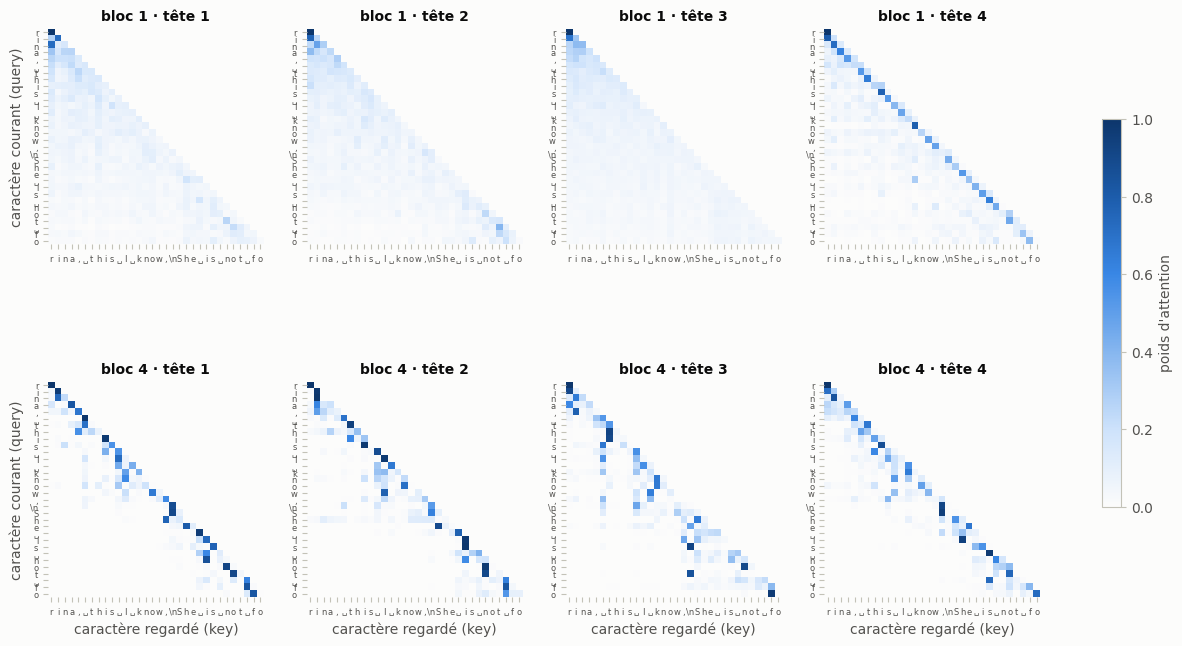

In [13]:
model.eval()
extrait = val_data[1000:1000 + block_size].unsqueeze(0).to(device)       # (1, T)
with torch.no_grad():
    model(extrait)
model.train()
etiquettes = [repr(c)[1:-1] if c != " " else "␣" for c in decode(extrait[0].tolist())]
print("Extrait :", repr(decode(extrait[0].tolist())))

carte = LinearSegmentedColormap.from_list("bleu", RAMPE_BLEUE)
fig, axes = plt.subplots(2, n_head, figsize=(4 * n_head, 8.4))
for ligne, num_bloc in enumerate([0, n_layer - 1]):
    for h in range(n_head):
        ax = axes[ligne, h]
        w = model.blocks[num_bloc].sa.heads[h].poids_attention[0].cpu().numpy()   # (T, T)
        im = ax.imshow(w, cmap=carte, vmin=0, vmax=1)
        ax.set_title(f"bloc {num_bloc + 1} · tête {h + 1}", fontsize=10)
        ax.set_xticks(range(block_size), etiquettes, fontsize=6)
        ax.set_yticks(range(block_size), etiquettes, fontsize=6)
        ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(False)
        if h == 0:
            ax.set_ylabel("caractère courant (query)")
        if ligne == 1:
            ax.set_xlabel("caractère regardé (key)")
fig.colorbar(im, ax=axes, shrink=0.6, label="poids d'attention")
plt.show()

**Comment lire ces cartes.**

- Une diagonale marquée : la tête regarde surtout le caractère courant, ou celui juste avant (motif de type « bigramme »).
- Une colonne marquée : beaucoup de caractères regardent le même caractère, souvent un espace ou un début de mot, qui sert de repère.
- Des poids étalés sur toute la ligne : la tête fait une moyenne du contexte, comme la moyenne causale du TP 2.

Les têtes d'un même bloc ont des motifs **différents** : c'est l'intérêt du multi-têtes, chaque tête apprend sa propre façon de regarder (cours, slide 50). Les motifs diffèrent aussi souvent entre le premier et le dernier bloc. Comme le rappelle le cours, ces spécialisations sont apprises et ne correspondent pas forcément à une règle linguistique claire.

## 11. Expériences (étape 9 de l'énoncé)

On teste l'effet de trois réglages en ne changeant **qu'une chose à la fois** par rapport à la configuration de référence (`block_size = 32`, 4 têtes, `dropout = 0`) :

1. la **longueur du contexte** : `block_size = 16`, puis 64 ;
2. le **nombre de têtes** à $n_{emb}$ constant : 1 tête de 64 dimensions au lieu de 4 têtes de 16 ;
3. le **dropout** : 0,2 au lieu de 0.

Pour garder un temps raisonnable, chaque configuration est entraînée sur un budget réduit et identique (3 000 itérations avec un GPU, 1 000 sans), avec la même graine. La référence est réentraînée sur ce même budget pour que la comparaison soit équitable.

Les classes lisent les constantes globales (étape 0). La fonction `experience` modifie donc temporairement ces constantes, entraîne un modèle neuf, puis les restaure.

In [14]:
ITERS_EXPE = 3000 if device == 'cuda' else 1000
EVAL_EXPE = ITERS_EXPE // 12
EVAL_ITERS_EXPE = 100


@torch.no_grad()
def estimer_perte(m, n_batches=EVAL_ITERS_EXPE):
    """Comme estimate_loss, mais pour n'importe quel modèle."""
    m.eval()
    out = {}
    for split in ['train', 'val']:
        out[split] = float(np.mean([m(*get_batch(split))[1].item() for _ in range(n_batches)]))
    m.train()
    return out


def experience(nom, **reglages):
    """Entraîne un modèle neuf avec certaines constantes globales modifiées, puis les restaure."""
    anciens = {k: globals()[k] for k in reglages}
    globals().update(reglages)
    try:
        torch.manual_seed(1337)
        m = BigramLanguageModel().to(device)
        opt = torch.optim.AdamW(m.parameters(), lr=learning_rate)
        courbe, t0 = [], time.time()
        for it in range(ITERS_EXPE + 1):
            if it % EVAL_EXPE == 0 or it == ITERS_EXPE:
                courbe.append({"itération": it, **estimer_perte(m)})
            if it == ITERS_EXPE:
                break
            xb, yb = get_batch('train')
            _, loss = m(xb, yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
        n_params = sum(p.numel() for p in m.parameters())
    finally:
        globals().update(anciens)
    courbe = pd.DataFrame(courbe)
    print(f"{nom:<26} val {courbe['val'].iloc[-1]:.3f}   train {courbe['train'].iloc[-1]:.3f}"
          f"   {n_params:,} paramètres   {time.time() - t0:.0f} s")
    return {"nom": nom, "courbe": courbe, "paramètres": n_params, "secondes": time.time() - t0, **reglages}


print(f"Budget par configuration : {ITERS_EXPE} itérations\n")
resultats = {
    "référence (32, 4 têtes, 0)": experience("référence (32, 4 têtes, 0)"),
    "block_size = 16": experience("block_size = 16", block_size=16),
    "block_size = 64": experience("block_size = 64", block_size=64),
    "1 tête de 64": experience("1 tête de 64", n_head=1),
    "dropout = 0,2": experience("dropout = 0,2", dropout=0.2),
}

Budget par configuration : 3000 itérations

référence (32, 4 têtes, 0) val 1.906   train 1.753   209,729 paramètres   88 s
block_size = 16            val 1.977   train 1.844   208,705 paramètres   89 s
block_size = 64            val 1.846   train 1.702   211,777 paramètres   91 s
1 tête de 64               val 1.901   train 1.737   209,729 paramètres   41 s
dropout = 0,2              val 1.965   train 1.862   209,729 paramètres   93 s


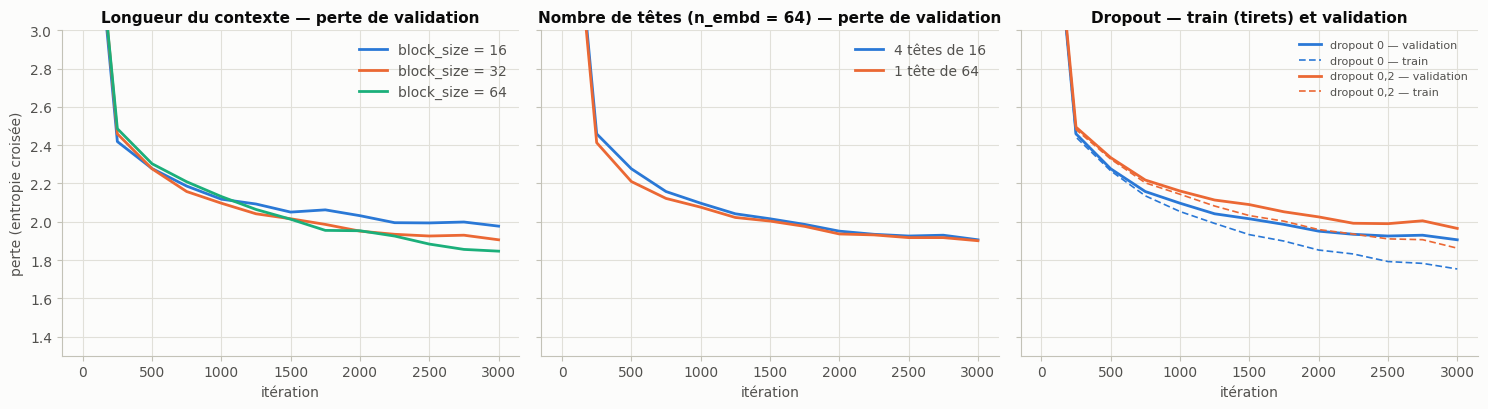

,perte val finale,perte train finale,écart val − train,écart à la référence (val),paramètres,secondes
configuration,,,,,,
"référence (32, 4 têtes, 0)",1.906,1.753,0.152,0.000,209729,87.960
block_size = 16,1.977,1.844,0.133,0.071,208705,88.738
block_size = 64,1.846,1.702,0.145,-0.059,211777,90.805
1 tête de 64,1.901,1.737,0.164,-0.005,209729,41.007
"dropout = 0,2",1.965,1.862,0.103,0.059,209729,92.538


In [15]:
ref = resultats["référence (32, 4 têtes, 0)"]
panneaux = [
    ("Longueur du contexte", [("block_size = 16", "block_size = 16"), ("block_size = 32", "référence (32, 4 têtes, 0)"),
                              ("block_size = 64", "block_size = 64")]),
    ("Nombre de têtes (n_embd = 64)", [("4 têtes de 16", "référence (32, 4 têtes, 0)"), ("1 tête de 64", "1 tête de 64")]),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (titre, series) in zip(axes[:2], panneaux):
    for couleur, (etiquette, cle) in zip(SERIES, series):
        c = resultats[cle]["courbe"]
        ax.plot(c["itération"], c["val"], color=couleur, label=etiquette)
    ax.set_title(f"{titre} — perte de validation")
    ax.set_xlabel("itération")
    ax.legend(loc="upper right")

ax = axes[2]
for couleur, (etiquette, cle) in zip(SERIES, [("dropout 0", "référence (32, 4 têtes, 0)"), ("dropout 0,2", "dropout = 0,2")]):
    c = resultats[cle]["courbe"]
    ax.plot(c["itération"], c["val"], color=couleur, label=f"{etiquette} — validation")
    ax.plot(c["itération"], c["train"], color=couleur, linewidth=1.2, linestyle=(0, (4, 2)),
            label=f"{etiquette} — train")
ax.set_title("Dropout — train (tirets) et validation")
ax.set_xlabel("itération")
ax.legend(loc="upper right", fontsize=8)
axes[0].set_ylabel("perte (entropie croisée)")
axes[0].set_ylim(1.3, 3.0)   # zoom sur la fin de l'entraînement (le départ, vers 4,17, sort du cadre)
plt.tight_layout()
plt.show()

synthese = pd.DataFrame([{
    "configuration": nom, "perte val finale": r["courbe"]["val"].iloc[-1],
    "perte train finale": r["courbe"]["train"].iloc[-1],
    "écart val − train": r["courbe"]["val"].iloc[-1] - r["courbe"]["train"].iloc[-1],
    "écart à la référence (val)": r["courbe"]["val"].iloc[-1] - ref["courbe"]["val"].iloc[-1],
    "paramètres": r["paramètres"], "secondes": r["secondes"],
} for nom, r in resultats.items()]).set_index("configuration")
synthese.round(3)

**Comment lire les expériences.** Les écarts de perte de l'ordre de 0,01 à 0,02 sont du bruit : l'estimation se fait sur 100 mini-batchs tirés au hasard.

1. **Longueur du contexte.**
   - Avec `block_size = 16`, chaque prédiction voit moins de texte : on attend une perte de validation **plus élevée**.
   - Avec 64, le modèle peut s'appuyer sur une ligne entière, souvent sur le nom du locuteur : on attend une perte **plus basse**, au prix d'un calcul plus long (l'attention coûte $T^2$, cours slide 44).
   - Le nombre de paramètres ne bouge presque pas : seule la table des positions grandit ($T \times 64$). **Allonger le contexte coûte du calcul, pas des paramètres.**
2. **Nombre de têtes.** Le nombre de paramètres est **identique** dans les deux cas : 4 têtes × 3 matrices de 64 × 16, ou 1 tête × 3 matrices de 64 × 64, soit 12 288 paramètres par couche dans les deux cas. Seule change la **façon de regarder**. Une seule tête produit une seule carte d'attention par couche, donc une seule moyenne pondérée du contexte. Quatre têtes peuvent suivre quatre relations à la fois (cours, slides 49 et 50). On attend un léger avantage pour 4 têtes ; s'il est faible ici, c'est que le modèle est petit et l'entraînement court.
3. **Dropout.** Il sert à réduire le sur-apprentissage. Comparez les écarts « val − train ».
   - **Si l'écart de la référence est faible**, le modèle ne sur-apprend pas encore : avec 0,2 million de paramètres pour un million de caractères, il est plutôt trop petit. Le dropout ralentit alors l'apprentissage, avec une perte train plus haute, sans améliorer la validation.
   - **Le dropout devient utile** quand l'écart grandit : modèle plus gros, ou entraînement beaucoup plus long. C'est exactement la consigne de l'énoncé : « augmenter dropout **si un surapprentissage apparaît** ».

In [16]:
# Lecture automatique des expériences
def ecart(nom):
    return synthese.loc[nom, "écart à la référence (val)"]

print(f"• Contexte : 16 -> {ecart('block_size = 16'):+.3f}, 64 -> {ecart('block_size = 64'):+.3f} "
      "de perte de validation par rapport à 32 (négatif = mieux).")
print(f"• Une tête de 64 au lieu de 4 têtes de 16 : {ecart('1 tête de 64'):+.3f}, à nombre de paramètres égal "
      f"({synthese.loc['1 tête de 64', 'paramètres']:,} contre {synthese.loc['référence (32, 4 têtes, 0)', 'paramètres']:,}).")
print(f"• Écart val − train : {synthese.loc['référence (32, 4 têtes, 0)', 'écart val − train']:+.3f} sans dropout, "
      f"{synthese.loc['dropout = 0,2', 'écart val − train']:+.3f} avec dropout 0,2 ; "
      f"effet du dropout sur la validation : {ecart('dropout = 0,2'):+.3f}.")

• Contexte : 16 -> +0.071, 64 -> -0.059 de perte de validation par rapport à 32 (négatif = mieux).
• Une tête de 64 au lieu de 4 têtes de 16 : -0.005, à nombre de paramètres égal (209,729 contre 209,729).
• Écart val − train : +0.152 sans dropout, +0.103 avec dropout 0,2 ; effet du dropout sur la validation : +0.059.
